# Previsão da Produção Eólica (*Wind*)

Componente: **Análise Exploratória e Preparação de Dados para Previsão Eólica (`capacity_factor`)** \
Período: **1 ano completo (8 760 registos horários)** \
Dataset: Ficheiro `Wind.csv` (fator de capacidade eólico normalizado no intervalo $[0, 1]$).

## Configuração e Carregamento dos Dados
O ficheiro `Wind.csv` é lido automaticamente a partir da pasta de trabalho. A série contém **8 760 registos horários** (365 dias × 24 horas), sem coluna explícita de data/hora. Reconstrói-se o índice horário contínuo para um ano padrão (`2021-01-01 00:00` a `2021-12-31 23:00`), extraindo variáveis temporais de suporte físico e meteorológico (como a hora, o mês e a estação do ano).

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (12, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

# Procura Wind.csv ou wind.csv
candidatos = [
    Path("Wind.csv"),
    Path("wind.csv"),
    *(p / "Wind.csv" for p in Path.cwd().parents),
]
ficheiro_wind = next((p for p in candidatos if p.is_file()), None)
if ficheiro_wind is None:
    raise FileNotFoundError("Coloca o ficheiro Wind.csv na pasta atual do Jupyter Notebook.")

df_raw = pd.read_csv(ficheiro_wind, skip_blank_lines=False)
col_alvo = "capacity_factor" if "capacity_factor" in df_raw.columns else df_raw.columns[0]
s = pd.to_numeric(df_raw[col_alvo], errors="coerce")

# Construção do índice temporal horário para 1 ano (8760 horas)
horas = pd.date_range("2021-01-01 00:00", periods=len(s), freq="h")
d = pd.DataFrame({"capacity_factor": s.values}, index=horas)
d.index.name = "data_hora"

d["hora"] = d.index.hour
d["dia_semana"] = d.index.dayofweek
d["mes"] = d.index.month
d["estacao"] = d["mes"].map({12: "Inverno", 1: "Inverno", 2: "Inverno",
                             3: "Primavera", 4: "Primavera", 5: "Primavera",
                             6: "Verão", 7: "Verão", 8: "Verão",
                             9: "Outono", 10: "Outono", 11: "Outono"})
d["dia_ano"] = d.index.dayofyear
d["hora_ano"] = (d["dia_ano"] - 1) * 24 + d["hora"]

print("Ficheiro carregado com sucesso:", ficheiro_wind.name)
d.head()

Ficheiro carregado com sucesso: Wind.csv


,capacity_factor,hora,dia_semana,mes,estacao,dia_ano,hora_ano
data_hora,,,,,,,
2021-01-01 00:00:00,0.000000,0,4,1,Inverno,1,0
2021-01-01 01:00:00,0.000000,1,4,1,Inverno,1,1
2021-01-01 02:00:00,0.054392,2,4,1,Inverno,1,2
2021-01-01 03:00:00,0.000000,3,4,1,Inverno,1,3
2021-01-01 04:00:00,0.048091,4,4,1,Inverno,1,4


---
# 4.1. Análise Exploratória dos Dados Eólicos (*Wind*)

## 4.1.1. Número de Registos e Integridade Temporal
O dataset dispõe exatamente de **8 760 registos horários**, correspondentes a um ano completo não bissexto (365 dias × 24 h). Verifica-se a distribuição e integridade temporal ao longo dos 12 meses do ano.

In [2]:
print("Nº total de registos horários:", len(d))
print("Início da série:", d.index.min(), "| Fim da série:", d.index.max())
print("\nDistribuição de registos por mês:")
print(d.groupby("mes").size().rename("registos").to_frame().T.to_string())

Nº total de registos horários: 8760
Início da série: 2021-01-01 00:00:00 | Fim da série: 2021-12-31 23:00:00

Distribuição de registos por mês:
mes        1    2    3    4    5    6    7    8    9    10   11   12
registos  744  672  744  720  744  720  744  744  720  744  720  744


## 4.1.2. Variável Alvo e Natureza Física do Vento
- **Variável a prever:** `capacity_factor` (Fator de Capacidade eólico).
- **Unidade e Domínio:** Grandeza adimensional no intervalo $[0, 1]$, representando a fração da potência nominal instalada gerada pelas turbinas eólicas.
- **Contexto Físico:** Ao contrário do consumo de edifícios (que segue padrões socioeconómicos e humanos estritos), a produção eólica é **altamente estocástica, intermitente e ditada pela meteorologia** (dinâmica de massas de ar, rugosidade do terreno e turbulência atmosférica).

## 4.1.3. Distribuição Estatística e Patamares de Produção Eólica
Dada a natureza bimodal e assimétrica típica da energia eólica (frequentes períodos de calmaria alternados com rajadas fortes), o fator de capacidade é analisado através de estatísticas descritivas globais e segmentado em **4 patamares operacionais**:
1. **Calmaria ($CF = 0$):** Vento abaixo da velocidade de arranque (*cut-in*).
2. **Baixa produção ($0 < CF \le 0.3$):** Regime sub-nominal comum.
3. **Média/Alta produção ($0.3 < CF \le 0.8$).**
4. **Produção máxima / Saturação ($CF > 0.8$):** Ventos fortes próximos da capacidade nominal.

,Valor
Estatística,
Mínimo,0.0000
Q1 (25%),0.0000
Mediana,0.0000
Média,0.0236
Q3 (75%),0.0000
Máximo,0.8721
Desvio Padrão,0.0636
Coef. Variação (CV),2.6900
Assimetria (Skew),4.5001


,Horas,Percentagem do Ano (%)
capacity_factor,,
Calmaria (CF = 0),6782,77.42
Baixa (0 - 0.3),1880,21.46
Média/Alta (0.3 - 0.8),97,1.11
Nominal/Pico (> 0.8),1,0.01


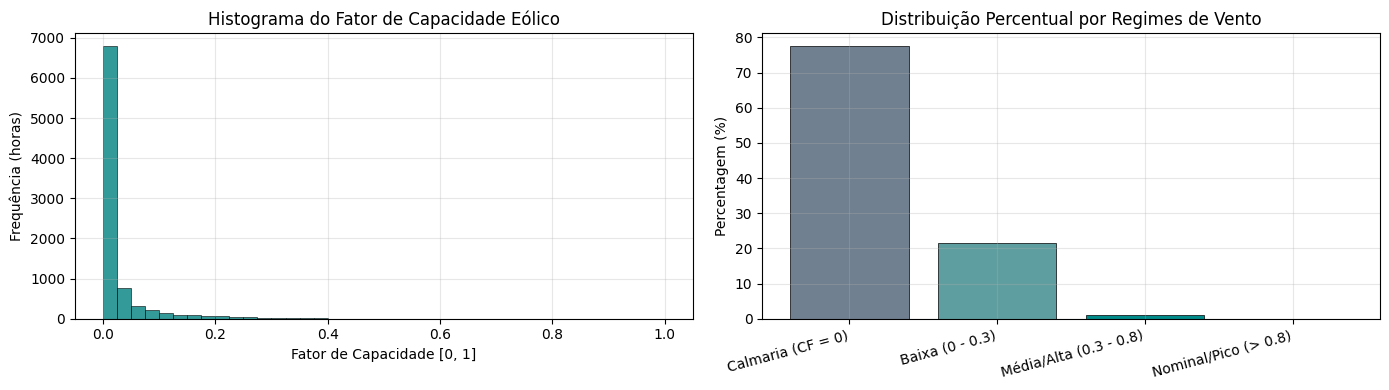

In [3]:
cf = d["capacity_factor"]

# Estatísticas descritivas globais
desc = cf.describe()
cv = cf.std() / cf.mean() if cf.mean() > 0 else np.nan
skew = cf.skew()

resumo_estatistico = pd.DataFrame({
    "Estatística": ["Mínimo", "Q1 (25%)", "Mediana", "Média", "Q3 (75%)", "Máximo", "Desvio Padrão", "Coef. Variação (CV)", "Assimetria (Skew)"],
    "Valor": [desc['min'], desc['25%'], desc['50%'], desc['mean'], desc['75%'], desc['max'], desc['std'], cv, skew]
}).set_index("Estatística")
display(resumo_estatistico.round(4))

# Patamares de operação eólica
classes = pd.cut(cf, bins=[-0.01, 0.0, 0.3, 0.8, 1.0], labels=["Calmaria (CF = 0)", "Baixa (0 - 0.3)", "Média/Alta (0.3 - 0.8)", "Nominal/Pico (> 0.8)"])
dist_classes = classes.value_counts().sort_index()

tabela_classes = pd.DataFrame({
    "Horas": dist_classes,
    "Percentagem do Ano (%)": (100 * dist_classes / len(cf)).round(2)
})
display(tabela_classes)

# Gráficos: Histograma e barras dos patamares
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].hist(cf, bins=40, range=(0, 1), color="teal", alpha=0.8, edgecolor="black", linewidth=0.5)
ax[0].set(title="Histograma do Fator de Capacidade Eólico", xlabel="Fator de Capacidade [0, 1]", ylabel="Frequência (horas)")

ax[1].bar(tabela_classes.index.astype(str), tabela_classes["Percentagem do Ano (%)"], color=["slategray", "cadetblue", "darkcyan", "teal"], edgecolor="black", linewidth=0.5)
ax[1].set(title="Distribuição Percentual por Regimes de Vento", ylabel="Percentagem (%)")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

## 4.1.4. Curva de Duração de Carga Eólica (*Wind Duration Curve*)
A curva de duração ordena o fator de capacidade por ordem decrescente ao longo das 8 760 horas do ano. Esta representação é fundamental na engenharia eólica para avaliar a disponibilidade energética e o número de horas em que o parque opera acima de um determinado limiar de potência.

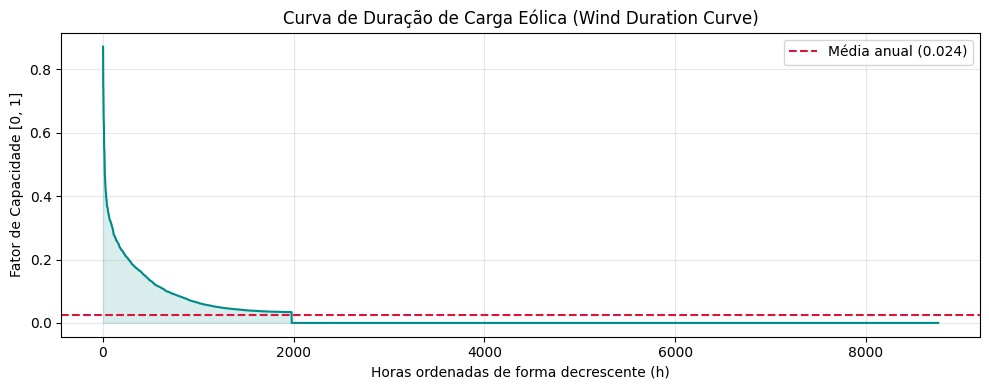

In [4]:
cf_ordenado = cf.sort_values(ascending=False).values
horas_acumuladas = np.arange(1, len(cf_ordenado) + 1)

plt.figure(figsize=(10, 4))
plt.plot(horas_acumuladas, cf_ordenado, color="darkcyan", lw=1.5)
plt.axhline(cf.mean(), color="crimson", ls="--", label=f"Média anual ({cf.mean():.3f})")
plt.fill_between(horas_acumuladas, cf_ordenado, color="darkcyan", alpha=0.15)
plt.title("Curva de Duração de Carga Eólica (Wind Duration Curve)")
plt.xlabel("Horas ordenadas de forma decrescente (h)")
plt.ylabel("Fator de Capacidade [0, 1]")
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

## 4.1.5. Análise de Taxas de Rampa (*Ramp Rates* - Variações Horárias)
As rampas de vento ($\Delta CF = CF_t - CF_{t-1}$) medem a volatilidade temporal e a velocidade com que a produção eólica sobe ou desce de uma hora para a outra. Variações bruscas representam o maior desafio operacional para a integração de energias renováveis na rede elétrica.

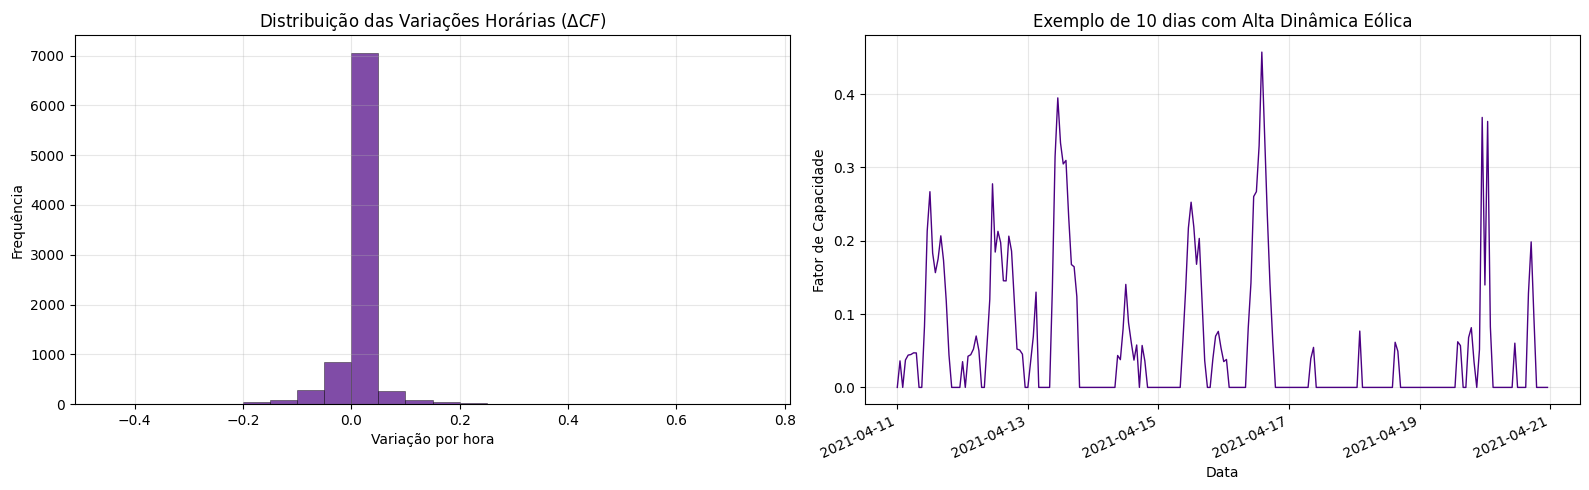

In [14]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Cálculo das rampas de vento
d["ramp"] = d["capacity_factor"].diff()
ramp = d["ramp"].dropna()

# Configuração da figura com largura maior para resolver a sobreposição de datas
fig, ax = plt.subplots(1, 2, figsize=(16, 5))

# 1. Primeiro gráfico: Histograma com caixas (bins) de 0.05 em 0.05
min_val = np.floor(ramp.min() / 0.05) * 0.05
max_val = np.ceil(ramp.max() / 0.05) * 0.05
bins = np.arange(min_val, max_val + 0.05, 0.05)

ax[0].hist(ramp, bins=bins, color="indigo", alpha=0.7, edgecolor="black", linewidth=0.4)
ax[0].set(title=r"Distribuição das Variações Horárias ($\Delta CF$)", 
          xlabel="Variação por hora", ylabel="Frequência")
ax[0].set_xticks(np.arange(-0.4, 0.9, 0.2))

# 2. Segundo gráfico: Período de 10 dias com espaço alargado e formatação de datas
bloco_amostra = d.iloc[2400:2640]["capacity_factor"]
ax[1].plot(bloco_amostra.index, bloco_amostra, color="indigo", lw=1)
ax[1].set(title=r"Exemplo de 10 dias com Alta Dinâmica Eólica", 
          xlabel="Data", ylabel="Fator de Capacidade")

# Formatação e espaçamento das datas no eixo X para não ficarem sobrepostas
ax[1].xaxis.set_major_locator(mdates.DayLocator(interval=2))  # Mostra um rótulo a cada 2 dias
ax[1].xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
plt.setp(ax[1].xaxis.get_majorticklabels(), rotation=25, ha="right")

plt.tight_layout()
plt.show()

## 4.1.6. Sazonalidade Mensal e Perfil Diário por Estação do Ano
Ao contrário do consumo elétrico (onde o perfil diário é ditado por dias úteis vs. fins de semana), na eólica o ciclo diário é condicionado por fenómenos térmicos e macroclimáticos. Analisamos a produção média mensal e o perfil diário médio segmentado por **estações do ano** (Inverno, Primavera, Verão e Outono).

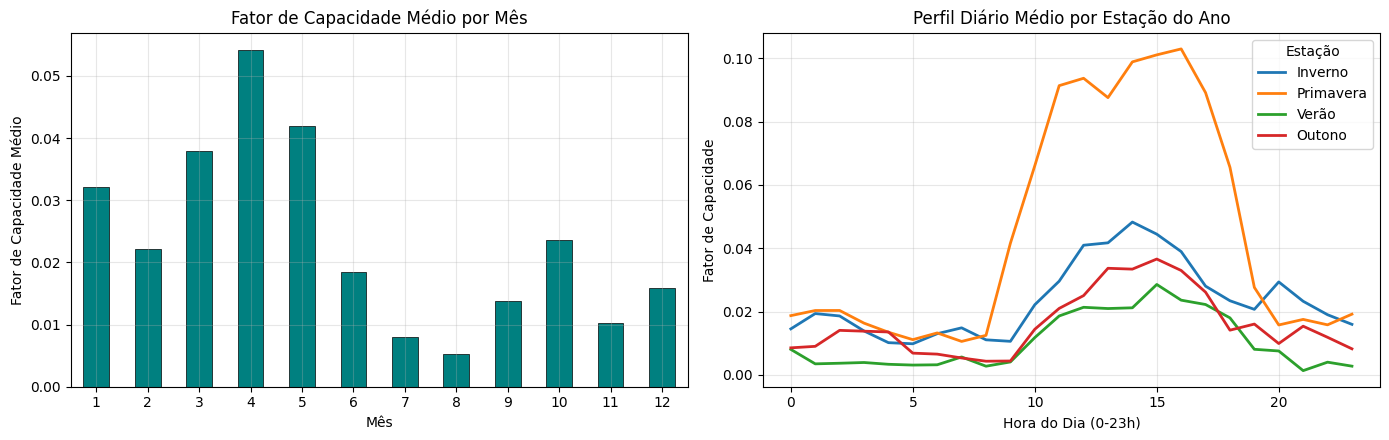

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))

# 1. Média mensal
mm = d.groupby("mes")["capacity_factor"].mean()
mm.plot(kind="bar", ax=ax[0], color="teal", edgecolor="black", linewidth=0.5)
ax[0].set(title="Fator de Capacidade Médio por Mês", xlabel="Mês", ylabel="Fator de Capacidade Médio")
ax[0].set_xticklabels(range(1, 13), rotation=0)

# 2. Perfil diário por estação
perfil_estacao = d.pivot_table(index="hora", columns="estacao", values="capacity_factor", aggfunc="mean")
ordem_estacoes = ["Inverno", "Primavera", "Verão", "Outono"]
perfil_estacao[ordem_estacoes].plot(ax=ax[1], lw=2)
ax[1].set(title="Perfil Diário Médio por Estação do Ano", xlabel="Hora do Dia (0-23h)", ylabel="Fator de Capacidade")
ax[1].legend(title="Estação")

plt.tight_layout()
plt.show()

## 4.1.7. Autocorrelação e Persistência do Vento
O vento exibe forte inércia física a curto prazo (horas consecutivas com produção correlacionada), cujo coeficiente de autocorrelação de Pearson desce acentuadamente à medida que o desfasamento (*lag*) aumenta.

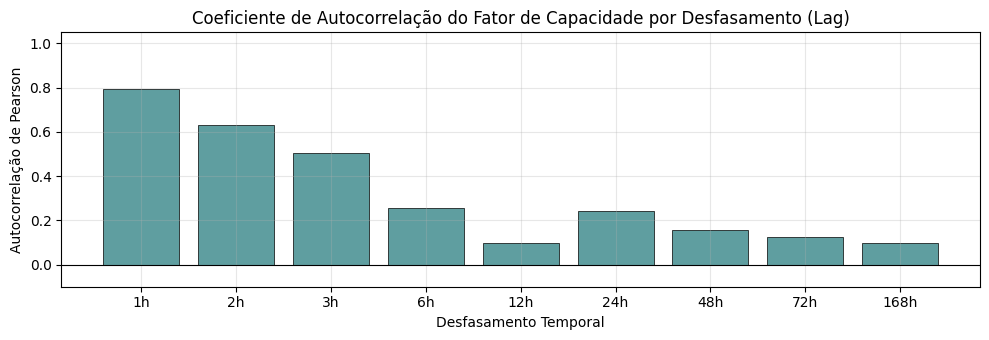

In [7]:
lags = [1, 2, 3, 6, 12, 24, 48, 72, 168]
ac_vals = {l: cf.autocorr(l) for l in lags}

plt.figure(figsize=(10, 3.5))
plt.bar([str(l) + "h" for l in lags], list(ac_vals.values()), color="cadetblue", edgecolor="black", linewidth=0.5)
plt.title("Coeficiente de Autocorrelação do Fator de Capacidade por Desfasamento (Lag)")
plt.xlabel("Desfasamento Temporal")
plt.ylabel("Autocorrelação de Pearson")
plt.ylim(-0.1, 1.05)
plt.axhline(0, color="black", lw=0.8)
plt.tight_layout()
plt.show()

## 4.1.8. Conclusões da Análise Exploratória
- **Natureza dos Dados:** Série horária de 8 760 registos com forte presença de calmaria ($CF = 0$, cerca de 77% do ano) e episódios pontuais de vento moderado a forte.
- **Dinâmica Temporal:** A produção eólica não apresenta dependência de dias úteis ou fins de semana, mas exibe modulações sazonais mensais e diárias associadas à meteorologia.
- **Autocorrelação:** Forte persistência nas primeiras horas (`lag 1h`, `2h`, `3h`), decaindo progressivamente e evidenciando o ciclo diário em `lag 24h`.

---
# 4.2. Preparação dos Dados para Modelação Preditiva

## 4.2.1. Verificação da Integridade e Ordenação Temporal
Garante-se que a série horária está estritamente ordenada no tempo e sem carimbos temporais repetidos.

In [8]:
dp = d.copy().sort_index(kind="stable")
s_prep = dp["capacity_factor"]

verif_temporal = pd.DataFrame([{
    "Total de Registos": len(s_prep),
    "Ordem Cronológica Estrita": s_prep.index.is_monotonic_increasing,
    "Sem Datas Duplicadas": s_prep.index.is_unique,
    "Data Inicial": s_prep.index.min(),
    "Data Final": s_prep.index.max()
}])
display(verif_temporal)

,Total de Registos,Ordem Cronológica Estrita,Sem Datas Duplicadas,Data Inicial,Data Final
0,8760,True,True,2021-01-01,2021-12-31 23:00:00


## 4.2.2. Tratamento de Valores em Falta e Calmaria Física
- Os valores iguais a `0` (`capacity_factor == 0`) representam **períodos reais de calmaria física** (vento abaixo da velocidade de arranque da turbina) e são rigorosamente preservados.
- Eventuais valores fora do intervalo físico $[0, 1]$ ou `NaN` são limpos, sem interpolações artificiais longas para evitar artefactos e *data leakage*.

In [9]:
dp["cf_original"] = dp["capacity_factor"]
invalido = dp["cf_original"].isna() | ~dp["cf_original"].between(0, 1)
dp["capacity_factor"] = dp["cf_original"].where(~invalido)

print(f"Registos inválidos ou NaN detetados: {invalido.sum()}")
print(f"Horas de calmaria física preservadas (CF = 0): {(dp['capacity_factor'] == 0).sum()} ({100 * (dp['capacity_factor'] == 0).mean():.1f}%)")

Registos inválidos ou NaN detetados: 0
Horas de calmaria física preservadas (CF = 0): 6782 (77.4%)


## 4.2.3. Deteção de Valores Atípicos (*Outliers* Meteorológicos)
Identificação de valores extremos com base no desvio em relação à média horária sazonal (`> 3 DP`). Na energia eólica, estes registos correspondem a rajadas extremas ou tempestades reais e são **mantidos no conjunto de dados** para que os modelos preditivos aprendam a lidar com picos severos.

Total de registos atípicos (> 3 DP): 280 (3.20%)


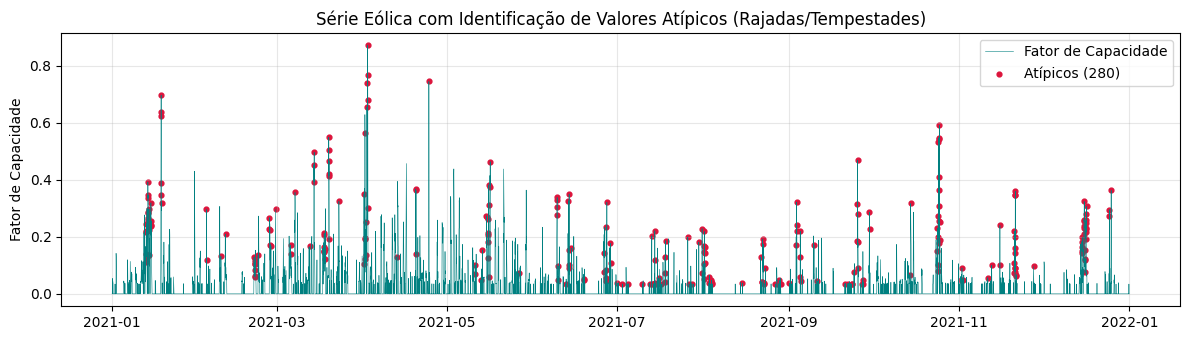

In [10]:
LIMIAR_DP = 3
chave = [dp["mes"], dp["hora"]]
media_h = dp.groupby(chave)["capacity_factor"].transform("mean")
dp_h = dp.groupby(chave)["capacity_factor"].transform("std")

dp["desvio_z"] = (dp["capacity_factor"] - media_h) / dp_h.replace(0, np.nan)
dp["atipico"] = dp["desvio_z"].abs() > LIMIAR_DP

print(f"Total de registos atípicos (> {LIMIAR_DP} DP): {dp['atipico'].sum()} ({100 * dp['atipico'].mean():.2f}%)")

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(dp.index, dp["capacity_factor"], lw=0.4, color="teal", label="Fator de Capacidade")
at = dp[dp["atipico"]]
ax.scatter(at.index, at["capacity_factor"], s=12, color="crimson", label=f"Atípicos ({len(at)})")
ax.set(title="Série Eólica com Identificação de Valores Atípicos (Rajadas/Tempestades)", ylabel="Fator de Capacidade")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

## 4.2.4. Verificação da Periodicidade Constante
Confirma-se que o intervalo entre registos consecutivos é exatamente de **1 hora** ao longo de todo o ano, sem saltos temporais.

In [11]:
dif = dp["hora_ano"].diff().dropna()

verif_period = pd.DataFrame([{
    "Intervalos Distintos": dif.nunique(),
    "Intervalo Horário (h)": int(dif.iloc[0]),
    "Saltos ≠ 1h": int((dif != 1).sum()),
    "Total de Dias Únicos": dp.index.normalize().nunique()
}])
display(verif_period)

,Intervalos Distintos,Intervalo Horário (h),Saltos ≠ 1h,Total de Dias Únicos
0,1,1,0,365


## 4.2.5. Engenharia de Variáveis Preditivas (*Features*) e Justificação
Para a previsão horária a $t+1h$, criam-se variáveis explicativas estritamente baseadas no passado (sem *data leakage*):
1. **Codificação Cíclica do Tempo:** $\sin$ e $\cos$ para a hora do dia ($24h$) e para o mês do ano ($12$ meses), garantindo continuidade nas transições temporais.
2. **Desfasamentos Históricos (*Lags*):** `cf_hora_anterior` ($t-1$), `cf_2h_antes` ($t-2$), `cf_3h_antes` ($t-3$), `cf_6h_antes` ($t-6$) e `cf_dia_anterior` ($t-24h$, captando o ciclo diurno).
3. **Taxa de Variação Recente (`ramp_recente`):** $\Delta CF$ entre $t-1$ e $t-2$.
4. **Exclusão de Variáveis Antropogénicas:** Variáveis como dias da semana ou fins de semana são excluídas por não terem significado físico na meteorologia.

In [12]:
# Codificação cíclica
dp["hora_sin"] = np.sin(2 * np.pi * dp["hora"] / 24)
dp["hora_cos"] = np.cos(2 * np.pi * dp["hora"] / 24)
dp["mes_sin"] = np.sin(2 * np.pi * (dp["mes"] - 1) / 12)
dp["mes_cos"] = np.cos(2 * np.pi * (dp["mes"] - 1) / 12)

# Lags temporais passados
lags_dict = {
    1: "cf_hora_anterior",
    2: "cf_2h_antes",
    3: "cf_3h_antes",
    6: "cf_6h_antes",
    24: "cf_dia_anterior",
}
for k, nome in lags_dict.items():
    dp[nome] = dp["capacity_factor"].shift(k)

dp["ramp_recente"] = dp["cf_hora_anterior"] - dp["cf_2h_antes"]

FEATURES_WIND = [
    "hora_sin",
    "hora_cos",
    "mes_sin",
    "mes_cos",
    "cf_hora_anterior",
    "cf_2h_antes",
    "cf_3h_antes",
    "cf_6h_antes",
    "cf_dia_anterior",
    "ramp_recente",
]

# Correlação de Pearson com a variável alvo
df_corr = dp.dropna(subset=FEATURES_WIND)
matriz_corr = df_corr[["capacity_factor"] + FEATURES_WIND].corr()[["capacity_factor"]].drop("capacity_factor").rename(columns={"capacity_factor": "Correlação de Pearson"}).round(3)
display(matriz_corr)

,Correlação de Pearson
hora_sin,-0.134
hora_cos,-0.176
mes_sin,0.164
mes_cos,0.063
cf_hora_anterior,0.795
cf_2h_antes,0.630
cf_3h_antes,0.506
cf_6h_antes,0.254
cf_dia_anterior,0.242
ramp_recente,0.257


## 4.2.6. Exportação do Dataset Preparado (`wind_preparado.csv`)
Salvaguarda dos dados limpos e com todas as variáveis calculadas na pasta `dataset/final/` (ou diretório de trabalho atual), prontos para a fase de modelação e previsão (secção 4.3).

In [13]:
colunas_finais = ["capacity_factor"] + FEATURES_WIND + ["cf_original", "atipico"]
dados_prontos = dp[colunas_finais]

raiz = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "dataset").exists()), Path.cwd())
pasta_final = (raiz / "dataset" / "final") if (raiz / "dataset").exists() else raiz
pasta_final.mkdir(parents=True, exist_ok=True)

caminho_saida = pasta_final / "wind_preparado.csv"
dados_prontos.to_csv(caminho_saida, index_label="data_hora")

print("Ficheiro guardado com sucesso em:", caminho_saida.resolve())
print("Dimensão final do dataset preparado:", dados_prontos.shape)
dados_prontos.iloc[[0, 1, 2, 3, 24, 25]].round(3)

Ficheiro guardado com sucesso em: C:\Users\DELL\Downloads\Energy_Consuption_Prediction\vasco\wind_preparado.csv
Dimensão final do dataset preparado: (8760, 13)


,capacity_factor,hora_sin,hora_cos,mes_sin,mes_cos,cf_hora_anterior,cf_2h_antes,cf_3h_antes,cf_6h_antes,cf_dia_anterior,ramp_recente,cf_original,atipico
data_hora,,,,,,,,,,,,,
2021-01-01 00:00:00,0.000,0.000,1.000,0.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,0.000,False
2021-01-01 01:00:00,0.000,0.259,0.966,0.0,1.0,0.000,NaN,NaN,NaN,NaN,NaN,0.000,False
2021-01-01 02:00:00,0.054,0.500,0.866,0.0,1.0,0.000,0.0,NaN,NaN,NaN,0.000,0.054,False
2021-01-01 03:00:00,0.000,0.707,0.707,0.0,1.0,0.054,0.0,0.0,NaN,NaN,0.054,0.000,False
2021-01-02 00:00:00,0.000,0.000,1.000,0.0,1.0,0.000,0.0,0.0,0.0,0.0,0.000,0.000,False
2021-01-02 01:00:00,0.035,0.259,0.966,0.0,1.0,0.000,0.0,0.0,0.0,0.0,0.000,0.035,False


## 4.2.7. Resumo da Preparação dos Dados Eólicos
- **Integridade Temporal:** 8 760 registos horários contínuos e ordenados sem falhas.
- **Tratamento Físico:** Preservação dos zeros de calmaria e sinalização de atípicos sem remoção destrutiva.
- **Engenharia de Features:** Criação de variáveis eológicas essenciais (lags de curto prazo, ciclo diário de 24h, rampas recentes e codificação trigonométrica), excluindo variáveis humanas irrelevantes.